# Singapore MRT Accessibility Mapper
## Discovering Connectivity Patterns in Singapore's Rail Network

**Project type:** Data Science mini-project / Exploratory Data Analysis / Geospatial Analysis  
**Academic level:** S.Y. B.Tech Information Technology

### Project purpose
This notebook investigates the geographical distribution of Singapore MRT and LRT stations using two downloaded CSV datasets. It explores station locations, nearest-neighbour distances, nearby-station counts, geographical clusters, and a small regression demonstration.

**Important interpretation note:** Distance between station coordinates is only a proxy for geographical proximity. It does not measure walking routes, station entrances, barriers, service frequency, or actual journey time.

### Dataset files used
1. `mrt_lrt_data.csv` — primary dataset with `station_name`, `type`, `lat`, and `lng`.
2. `MRT Stations.csv` — supplementary dataset with station names, station codes, coordinates, and geometry text.

The datasets are kept separate initially. They may describe overlapping stations and should not be blindly appended or merged. Record-level matching and coverage checks are performed before any optional enrichment.

**Source URLs to document in the final report**
- https://www.kaggle.com/datasets/yxlee245/singapore-train-station-coordinates
- https://www.kaggle.com/datasets/shengjunlim/singapore-mrt-lrt-stations-with-coordinates

TEAM MEMBERS :
NAME                 PRN
1)Siddharth  Kabade  125B1F134
2)Mahesh Shirame     125B1F168
3)Shukhraj Girme     125B1F147

## 1. Environment and imports

Run this notebook from the extracted project folder. If required libraries are missing, install them in your project virtual environment:

```bash
python -m pip install pandas numpy matplotlib seaborn scikit-learn scipy folium
```

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, mannwhitneyu
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

# Support running from either the project root or the notebooks/ directory.
cwd = Path.cwd()
if (cwd / "data" / "raw").exists():
    PROJECT_DIR = cwd
elif (cwd.parent / "data" / "raw").exists():
    PROJECT_DIR = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find data/raw. Open this notebook from the project root "
        "or the notebooks/ directory."
    )

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
MAPS_DIR = PROJECT_DIR / "outputs" / "maps"
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"

for folder in [PROCESSED_DIR, FIGURES_DIR, MAPS_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Raw data folder:", RAW_DIR)

Project folder: /home/rolex/Downloads/singapore-mrt-accessibility-mapper
Raw data folder: /home/rolex/Downloads/singapore-mrt-accessibility-mapper/data/raw


## 2. Load and inspect the real datasets

This section reads the supplied CSV files. It does not create synthetic replacement data: if a file is missing, the notebook stops with a clear error.

In [2]:
primary_path = RAW_DIR / "mrt_lrt_data.csv"
supplementary_path = RAW_DIR / "MRT Stations.csv"

for path in [primary_path, supplementary_path]:
    if not path.exists():
        raise FileNotFoundError(
            f"Required file not found: {path}\n"
            "Keep both supplied CSV files inside data/raw/."
        )

primary_raw = pd.read_csv(primary_path)
supplementary_raw = pd.read_csv(supplementary_path)

print("Primary dataset shape:", primary_raw.shape)
print("Primary columns:", primary_raw.columns.tolist())
display(primary_raw.head())

print("\nSupplementary dataset shape:", supplementary_raw.shape)
print("Supplementary columns:", supplementary_raw.columns.tolist())
display(supplementary_raw.head())

Primary dataset shape: (157, 4)
Primary columns: ['station_name', 'type', 'lat', 'lng']


,station_name,type,lat,lng
0,Jurong East,MRT,1.333207,103.742308
1,Bukit Batok,MRT,1.349069,103.749596
2,Bukit Gombak,MRT,1.359043,103.751863
3,Choa Chu Kang,MRT,1.385417,103.744316
4,Yew Tee,MRT,1.397383,103.747523



Supplementary dataset shape: (171, 7)
Supplementary columns: ['Unnamed: 0', 'OBJECTID', 'STN_NAME', 'STN_NO', 'geometry', 'Latitude', 'Longitude']


,Unnamed: 0,OBJECTID,STN_NAME,STN_NO,geometry,Latitude,Longitude
0,0,1,EUNOS MRT STATION,EW7,POINT (103.9032524667383 1.319778951553637),1.319779,103.903252
1,1,2,CHINESE GARDEN MRT STATION,EW25,POINT (103.7325967380734 1.342352820874744),1.342353,103.732597
2,2,3,KHATIB MRT STATION,NS14,POINT (103.8329799077383 1.417383370153547),1.417383,103.832980
3,3,4,KRANJI MRT STATION,NS7,POINT (103.7621654109002 1.425177698770448),1.425178,103.762165
4,4,5,REDHILL MRT STATION,EW18,POINT (103.816816670149 1.289562726402453),1.289563,103.816817


### 2.1 Data quality checks

We inspect missing values, exact duplicate rows, data types, and coordinate ranges. Plausible Singapore coordinate ranges are used as a basic validation check, not as proof that every station is correct.

In [3]:
def quality_summary(frame, dataset_name):
    summary = pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing_count": frame.isna().sum(),
        "missing_percent": (frame.isna().mean() * 100).round(2),
        "unique_values": frame.nunique(dropna=True),
    })
    print(f"{dataset_name}: {frame.shape[0]} rows x {frame.shape[1]} columns")
    print("Exact duplicate rows:", int(frame.duplicated().sum()))
    display(summary)
    return summary

primary_quality = quality_summary(primary_raw, "Primary dataset")
supplementary_quality = quality_summary(supplementary_raw, "Supplementary dataset")

Primary dataset: 157 rows x 4 columns
Exact duplicate rows: 0


,dtype,missing_count,missing_percent,unique_values
station_name,str,0,0.0,157
type,str,0,0.0,2
lat,float64,0,0.0,155
lng,float64,0,0.0,156


Supplementary dataset: 171 rows x 7 columns
Exact duplicate rows: 0


,dtype,missing_count,missing_percent,unique_values
Unnamed: 0,int64,0,0.0,171
OBJECTID,int64,0,0.0,171
STN_NAME,str,0,0.0,171
STN_NO,str,0,0.0,171
geometry,str,0,0.0,171
Latitude,float64,0,0.0,171
Longitude,float64,0,0.0,171


## 3. Clean the primary station dataset

The primary file explicitly includes MRT/LRT type. We standardize column names, remove only exact duplicate rows, convert coordinates to numeric values, and flag invalid records. We do not drop stations merely because their names resemble another station's name.

In [4]:
required_primary = {"station_name", "type", "lat", "lng"}
missing_columns = required_primary - set(primary_raw.columns)
if missing_columns:
    raise ValueError(f"Primary dataset is missing required columns: {sorted(missing_columns)}")

stations = primary_raw.copy()
stations.columns = stations.columns.str.strip().str.lower()
stations["station_name"] = stations["station_name"].astype("string").str.strip()
stations["type"] = stations["type"].astype("string").str.strip().str.upper()
stations["lat"] = pd.to_numeric(stations["lat"], errors="coerce")
stations["lng"] = pd.to_numeric(stations["lng"], errors="coerce")

rows_before = len(stations)
exact_duplicates = int(stations.duplicated().sum())
stations = stations.drop_duplicates().copy()

# Broad geographic bounds around Singapore; use as a validation flag.
valid_name = stations["station_name"].notna() & stations["station_name"].str.len().gt(0)
valid_type = stations["type"].isin(["MRT", "LRT"])
valid_coords = (
    stations["lat"].between(1.15, 1.50)
    & stations["lng"].between(103.55, 104.10)
)
stations["record_valid"] = valid_name & valid_type & valid_coords

invalid_primary = stations.loc[~stations["record_valid"]].copy()
clean_stations = stations.loc[stations["record_valid"]].drop(columns="record_valid").copy()

print(f"Rows before exact-duplicate removal: {rows_before}")
print(f"Exact duplicate rows removed: {exact_duplicates}")
print(f"Invalid records flagged: {len(invalid_primary)}")
print(f"Valid records retained: {len(clean_stations)}")
print("\nStation type counts:")
display(clean_stations["type"].value_counts().rename_axis("type").to_frame("count"))

if not invalid_primary.empty:
    print("Invalid records for manual inspection:")
    display(invalid_primary)

clean_path = PROCESSED_DIR / "mrt_lrt_stations_clean.csv"
invalid_path = RESULTS_DIR / "invalid_primary_records.csv"
clean_stations.to_csv(clean_path, index=False)
invalid_primary.to_csv(invalid_path, index=False)
print("Cleaned dataset saved to:", clean_path)

Rows before exact-duplicate removal: 157
Exact duplicate rows removed: 0
Invalid records flagged: 0
Valid records retained: 157

Station type counts:


,count
type,
MRT,119
LRT,38


Cleaned dataset saved to: /home/rolex/Downloads/singapore-mrt-accessibility-mapper/data/processed/mrt_lrt_stations_clean.csv


## 4. Inspect the supplementary MRT station dataset

This file contains station codes and coordinates but does not explicitly label LRT stations. Station codes can contain more than one line code for interchanges. We therefore keep the file separate and do not treat it as a complete line-level dataset.

In [5]:
required_supp = {"STN_NAME", "STN_NO", "Latitude", "Longitude"}
missing_supp = required_supp - set(supplementary_raw.columns)
if missing_supp:
    raise ValueError(f"Supplementary dataset is missing required columns: {sorted(missing_supp)}")

supp = supplementary_raw.copy()
supp["STN_NAME"] = supp["STN_NAME"].astype("string").str.strip()
supp["STN_NO"] = supp["STN_NO"].astype("string").str.strip()
supp["Latitude"] = pd.to_numeric(supp["Latitude"], errors="coerce")
supp["Longitude"] = pd.to_numeric(supp["Longitude"], errors="coerce")
supp["station_name_normalized"] = (
    supp["STN_NAME"].str.upper()
    .str.replace(r"\s+MRT STATION$", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Supplementary rows:", len(supp))
print("Missing station names:", int(supp["STN_NAME"].isna().sum()))
print("Missing station codes:", int(supp["STN_NO"].isna().sum()))
print("Missing coordinates:", int(supp[["Latitude", "Longitude"]].isna().any(axis=1).sum()))
display(supp[["STN_NAME", "STN_NO", "Latitude", "Longitude"]].head(10))

Supplementary rows: 171
Missing station names: 0
Missing station codes: 0
Missing coordinates: 0


,STN_NAME,STN_NO,Latitude,Longitude
0,EUNOS MRT STATION,EW7,1.319779,103.903252
1,CHINESE GARDEN MRT STATION,EW25,1.342353,103.732597
2,KHATIB MRT STATION,NS14,1.417383,103.832980
3,KRANJI MRT STATION,NS7,1.425178,103.762165
4,REDHILL MRT STATION,EW18,1.289563,103.816817
5,YEW TEE MRT STATION,NS5,1.397535,103.747405
6,PIONEER MRT STATION,EW28,1.337587,103.697322
7,COMMONWEALTH MRT STATION,EW20,1.302439,103.798305
8,PAYA LEBAR MRT STATION,EW8/CC9,1.318112,103.893060
9,SIMEI MRT STATION,EW3,1.343203,103.953372


## 5. Compare station names across the two sources

This is a conservative name-based comparison after removing the phrase `MRT STATION` and normalizing spaces/case. It is an initial audit only: different naming conventions may cause false non-matches, and similar names do not prove that records represent the same physical station.

In [6]:
primary_compare = clean_stations.copy()
primary_compare["station_name_normalized"] = (
    primary_compare["station_name"].astype(str).str.upper()
    .str.replace(r"\s+", " ", regex=True).str.strip()
)

primary_names = set(primary_compare["station_name_normalized"])
supp_names = set(supp["station_name_normalized"].dropna())

matched_names = sorted(primary_names & supp_names)
primary_only_names = sorted(primary_names - supp_names)
supp_only_names = sorted(supp_names - primary_names)

print("Unique primary names:", len(primary_names))
print("Unique supplementary names:", len(supp_names))
print("Exact normalized name matches:", len(matched_names))
print("Names only in primary dataset:", len(primary_only_names))
print("Names only in supplementary dataset:", len(supp_only_names))

print("\nMatched names (first 20):")
display(pd.DataFrame({"matched_station_name": matched_names}).head(20))

print("\nPrimary-only names (first 20):")
display(pd.DataFrame({"primary_only_station_name": primary_only_names}).head(20))

print("\nSupplementary-only names (first 20):")
display(pd.DataFrame({"supplementary_only_station_name": supp_only_names}).head(20))

name_audit = pd.DataFrame({
    "match_category": (
        ["matched"] * len(matched_names)
        + ["primary_only"] * len(primary_only_names)
        + ["supplementary_only"] * len(supp_only_names)
    ),
    "station_name_normalized": matched_names + primary_only_names + supp_only_names
})
name_audit.to_csv(RESULTS_DIR / "station_name_match_audit.csv", index=False)

Unique primary names: 157
Unique supplementary names: 171
Exact normalized name matches: 119
Names only in primary dataset: 38
Names only in supplementary dataset: 52

Matched names (first 20):


,matched_station_name
0,ADMIRALTY
1,ALJUNIED
2,ANG MO KIO
3,BARTLEY
4,BAYFRONT
5,BEAUTY WORLD
6,BEDOK
7,BEDOK NORTH
8,BEDOK RESERVOIR
9,BENCOOLEN



Primary-only names (first 20):


,primary_only_station_name
0,BAKAU
1,BANGKIT
2,CHENG LIM
3,COMPASSVALE
4,CORAL EDGE
5,COVE
6,DAMAI
7,FAJAR
8,FARMWAY
9,FERNVALE



Supplementary-only names (first 20):


,supplementary_only_station_name
0,BAKAU LRT STATION
1,BANGKIT LRT STATION
2,BRIGHT HILL
3,BUKIT BROWN
4,BUKIT PANJANG LRT STATION
5,CANBERRA
6,CHENG LIM LRT STATION
7,CHOA CHU KANG LRT STATION
8,COMPASSVALE LRT STATION
9,CORAL EDGE LRT STATION


## 6. Exploratory data analysis (EDA)

The following tables and charts describe the primary dataset only. Counts refer to records in this file, not necessarily to every current station in Singapore.

Clean dataset overview
Station records: 157
Unique station names: 157
Station types: {'MRT': 119, 'LRT': 38}


,count,mean,std,min,25%,50%,75%,max
lat,157.0,1.345080,0.044289,1.265453,1.308474,1.337649,1.384116,1.449133
lng,157.0,103.841362,0.068544,103.636866,103.790046,103.851550,103.893133,103.988487


,Station type,Station count
0,MRT,119
1,LRT,38


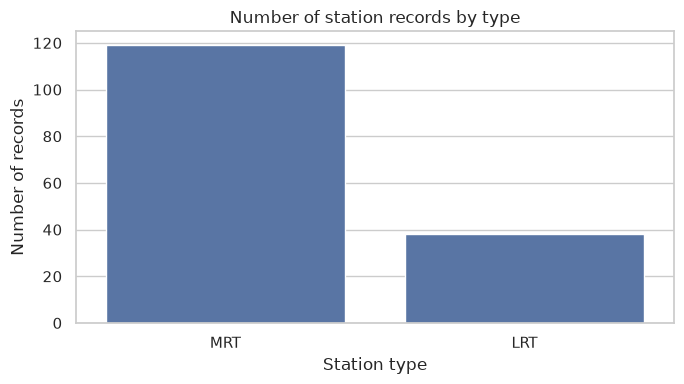

In [7]:
print("Clean dataset overview")
print("Station records:", len(clean_stations))
print("Unique station names:", clean_stations["station_name"].nunique())
print("Station types:", clean_stations["type"].value_counts().to_dict())

summary_stats = clean_stations[["lat", "lng"]].describe().T
display(summary_stats)

type_counts = clean_stations["type"].value_counts().rename_axis("Station type").reset_index(name="Station count")
display(type_counts)

plt.figure(figsize=(7, 4))
sns.countplot(data=clean_stations, x="type", order=clean_stations["type"].value_counts().index)
plt.title("Number of station records by type")
plt.xlabel("Station type")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "station_counts_by_type.png", dpi=160)
plt.show()

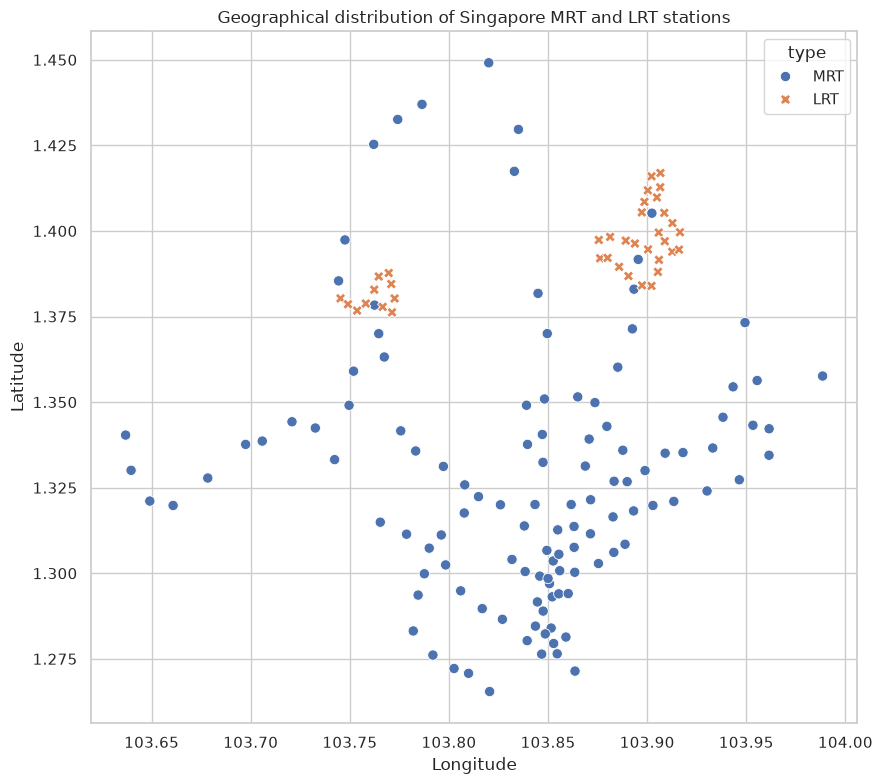

In [8]:
plt.figure(figsize=(9, 8))
sns.scatterplot(
    data=clean_stations, x="lng", y="lat",
    hue="type", style="type", s=55
)
plt.title("Geographical distribution of Singapore MRT and LRT stations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "station_geographical_scatter.png", dpi=160)
plt.show()

### Interpretation reminder
A scatter plot helps reveal spatial concentration and broad coverage. It cannot show actual walking accessibility, rail connections, service frequency, or travel time.

## 7. Geospatial distance analysis

We use the Haversine formula to estimate great-circle distances between coordinates. Distances are returned in kilometres. This is more appropriate than applying ordinary Euclidean distance directly to raw latitude/longitude values.

In [9]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in kilometres between two latitude/longitude points."""
    earth_radius_km = 6371.0088
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 2 * earth_radius_km * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


coords = clean_stations[["lat", "lng"]].to_numpy(dtype=float)
n = len(coords)
if n < 2:
    raise ValueError("At least two valid stations are required for nearest-neighbour analysis.")

distance_matrix = np.zeros((n, n), dtype=float)
for i in range(n):
    distance_matrix[i, :] = haversine_km(
        coords[i, 0], coords[i, 1], coords[:, 0], coords[:, 1]
    )
np.fill_diagonal(distance_matrix, np.inf)

nearest_indices = distance_matrix.argmin(axis=1)
nearest_km = distance_matrix.min(axis=1)

analysis = clean_stations.reset_index(drop=True).copy()
analysis["nearest_station_name"] = clean_stations["station_name"].iloc[nearest_indices].to_numpy()
analysis["nearest_station_type"] = clean_stations["type"].iloc[nearest_indices].to_numpy()
analysis["nearest_distance_km"] = nearest_km
analysis["nearest_distance_m"] = nearest_km * 1000

# Count OTHER stations within 500 m and 1 km.
analysis["stations_within_500m"] = (distance_matrix < 0.5).sum(axis=1)
analysis["stations_within_1km"] = (distance_matrix < 1.0).sum(axis=1)

print("Nearest-neighbour distance summary (km):")
display(analysis["nearest_distance_km"].describe().to_frame("nearest_distance_km"))
display(analysis.sort_values("nearest_distance_km").head(10)[
    ["station_name", "type", "nearest_station_name", "nearest_distance_m",
     "stations_within_500m", "stations_within_1km"]
])

analysis.to_csv(PROCESSED_DIR / "mrt_lrt_stations_with_distances.csv", index=False)

Nearest-neighbour distance summary (km):


,nearest_distance_km
count,157.000000
mean,0.852131
std,0.466590
min,0.000000
25%,0.484394
50%,0.819004
75%,1.137331
max,3.454048


,station_name,type,nearest_station_name,nearest_distance_m,stations_within_500m,stations_within_1km
7,Woodlands,MRT,Admiralty,0.000000,1,1
8,Admiralty,MRT,Woodlands,0.000000,1,1
107,Bencoolen,MRT,Bras Basah,185.435522,2,9
72,Bras Basah,MRT,Bencoolen,185.435522,2,8
156,Soo Teck,LRT,Sumang,370.970214,1,4
155,Sumang,LRT,Soo Teck,370.970214,2,5
150,Sam Kee,LRT,Teck Lee,377.981642,1,8
151,Teck Lee,LRT,Sam Kee,377.981642,2,6
22,City Hall,MRT,Esplanade,380.314023,2,8
73,Esplanade,MRT,City Hall,380.314023,1,5


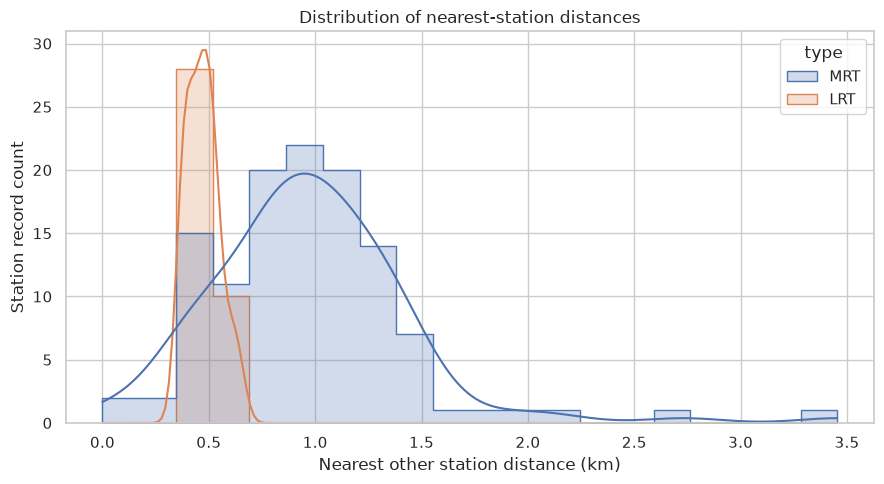

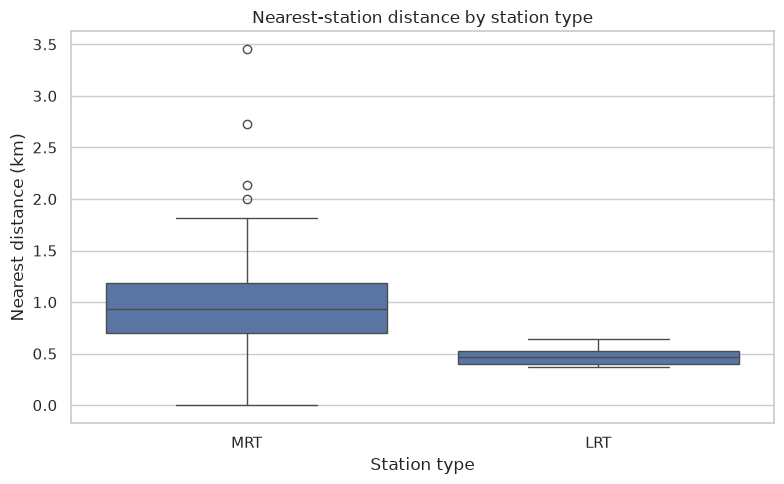

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(data=analysis, x="nearest_distance_km", hue="type", bins=20, kde=True, element="step")
plt.title("Distribution of nearest-station distances")
plt.xlabel("Nearest other station distance (km)")
plt.ylabel("Station record count")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "nearest_distance_histogram.png", dpi=160)
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=analysis, x="type", y="nearest_distance_km")
plt.title("Nearest-station distance by station type")
plt.xlabel("Station type")
plt.ylabel("Nearest distance (km)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "nearest_distance_by_type.png", dpi=160)
plt.show()

### 7.1 Summarize proximity by station type

In [11]:
proximity_by_type = analysis.groupby("type").agg(
    station_records=("station_name", "count"),
    mean_nearest_distance_km=("nearest_distance_km", "mean"),
    median_nearest_distance_km=("nearest_distance_km", "median"),
    std_nearest_distance_km=("nearest_distance_km", "std"),
    mean_stations_within_500m=("stations_within_500m", "mean"),
    mean_stations_within_1km=("stations_within_1km", "mean"),
).round(3)
display(proximity_by_type)
proximity_by_type.to_csv(RESULTS_DIR / "proximity_summary_by_type.csv")

,station_records,mean_nearest_distance_km,median_nearest_distance_km,std_nearest_distance_km,mean_stations_within_500m,mean_stations_within_1km
type,,,,,,
LRT,38,0.472,0.464,0.076,0.763,4.763
MRT,119,0.974,0.935,0.474,0.210,1.723


## 8. Simple hypothesis test: MRT versus LRT proximity

**Null hypothesis (H₀):** The mean nearest-neighbour distance is equal for MRT and LRT station records.  
**Alternative hypothesis (H₁):** The mean nearest-neighbour distance differs between MRT and LRT station records.  
**Significance level:** 0.05.

Welch's independent t-test does not assume equal variances. Station locations are spatially dependent, however, so the p-value should be interpreted cautiously. This is an exploratory comparison, not evidence of causation.

In [12]:
mrt_dist = analysis.loc[analysis["type"] == "MRT", "nearest_distance_km"].dropna()
lrt_dist = analysis.loc[analysis["type"] == "LRT", "nearest_distance_km"].dropna()

print(f"MRT records: {len(mrt_dist)}")
print(f"LRT records: {len(lrt_dist)}")

if len(mrt_dist) >= 2 and len(lrt_dist) >= 2:
    t_stat, p_value = ttest_ind(mrt_dist, lrt_dist, equal_var=False)
    print(f"Welch t-statistic: {t_stat:.4f}")
    print(f"p-value: {p_value:.6f}")
    if p_value < 0.05:
        print("At alpha=0.05, reject H0. The sample means differ statistically in this test.")
    else:
        print("At alpha=0.05, do not reject H0. The test does not provide sufficient evidence of a mean difference.")
    print("Caution: spatial dependence and category/network structure limit the interpretation.")
else:
    print("Not enough observations in both categories for this test.")

MRT records: 119
LRT records: 38
Welch t-statistic: 11.1105
p-value: 0.000000
At alpha=0.05, reject H0. The sample means differ statistically in this test.
Caution: spatial dependence and category/network structure limit the interpretation.


## 9. K-Means geographical clustering

For clustering, we project latitude/longitude to a local metric coordinate approximation suitable for this small Singapore study: longitude is scaled by cosine of the mean latitude, and both axes are converted approximately to kilometres. This is a simple local approximation, not a formal map projection.

We compare a small range of cluster counts using inertia (elbow method) and silhouette score. These are exploratory criteria; the chosen clusters are not official transport zones and do not prove connectivity.

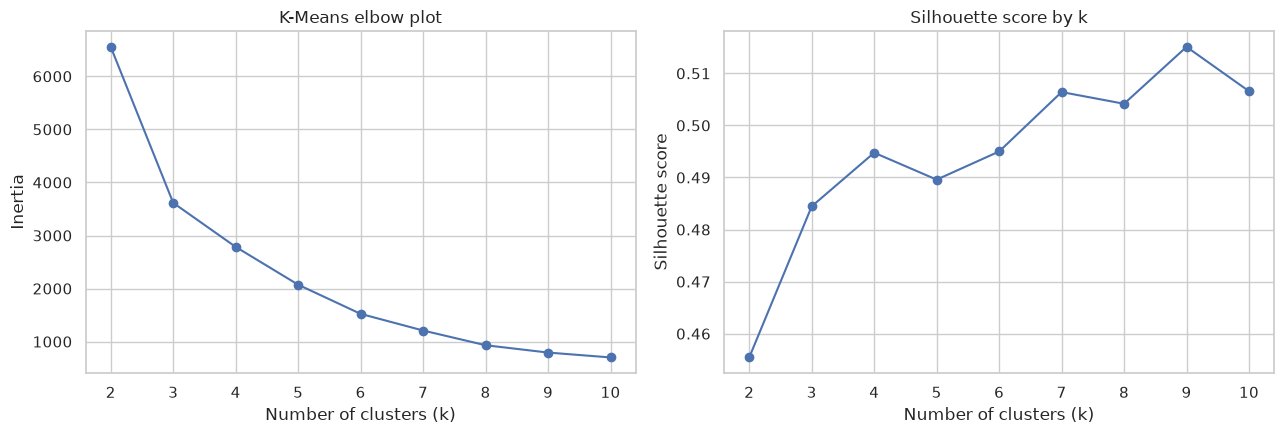

Exploratory k selected by highest silhouette score: 9


In [13]:
mean_lat_rad = np.radians(clean_stations["lat"].mean())
cluster_xy = np.column_stack([
    clean_stations["lng"].to_numpy() * 111.320 * np.cos(mean_lat_rad),
    clean_stations["lat"].to_numpy() * 110.574,
])
max_k = min(10, len(clean_stations) - 1)
k_values = list(range(2, max_k + 1))
inertias, silhouettes = [], []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(cluster_xy)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(cluster_xy, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("K-Means elbow plot")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouettes, marker="o")
axes[1].set_title("Silhouette score by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "kmeans_model_selection.png", dpi=160)
plt.show()

best_k = k_values[int(np.argmax(silhouettes))]
print("Exploratory k selected by highest silhouette score:", best_k)

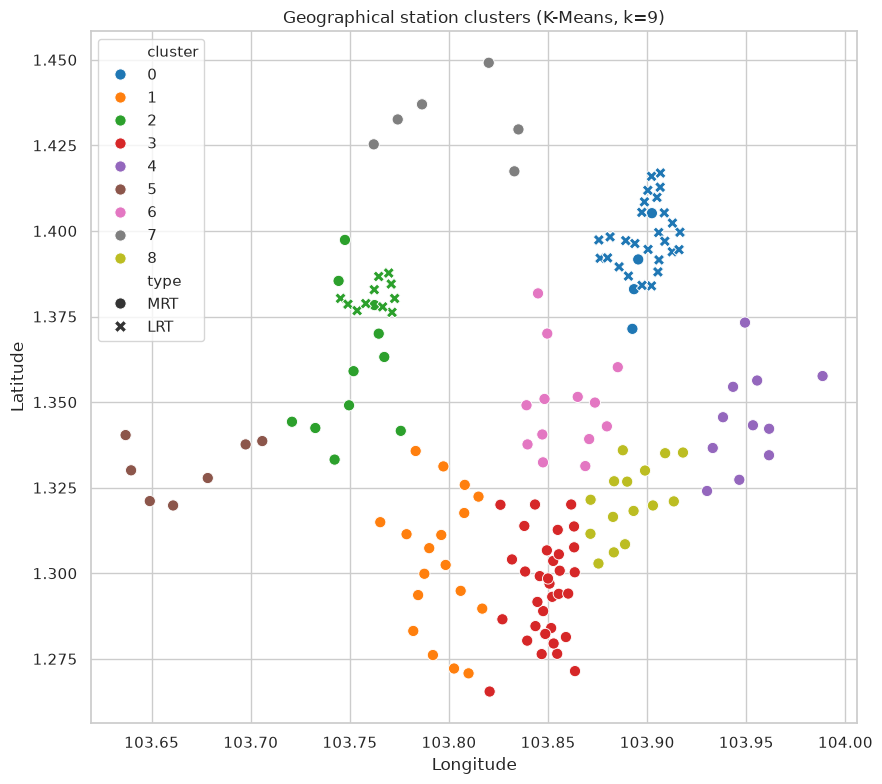

,station_records,mean_latitude,mean_longitude,mrt_records,lrt_records
cluster,,,,,
0,31,1.3973,103.8989,4,27
1,18,1.3033,103.7956,18,0
2,22,1.3707,103.7565,11,11
3,33,1.2956,103.8488,33,0
4,11,1.3450,103.9510,11,0
5,7,1.3308,103.6669,7,0
6,13,1.3490,103.8584,13,0
7,7,1.4326,103.7996,7,0
8,15,1.3211,103.8913,15,0


In [14]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
analysis["cluster"] = kmeans.fit_predict(cluster_xy)

plt.figure(figsize=(9, 8))
sns.scatterplot(
    data=analysis, x="lng", y="lat",
    hue="cluster", palette="tab10", style="type", s=65
)
plt.title(f"Geographical station clusters (K-Means, k={best_k})")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "kmeans_station_clusters.png", dpi=160)
plt.show()

cluster_summary = analysis.groupby("cluster").agg(
    station_records=("station_name", "count"),
    mean_latitude=("lat", "mean"),
    mean_longitude=("lng", "mean"),
    mrt_records=("type", lambda s: int((s == "MRT").sum())),
    lrt_records=("type", lambda s: int((s == "LRT").sum())),
).round(4)
display(cluster_summary)
cluster_summary.to_csv(RESULTS_DIR / "kmeans_cluster_summary.csv")

## 10. Simple regression demonstration

The target is each station's nearest-neighbour distance. Features are latitude and longitude. We compare Linear Regression with a Decision Tree Regressor using a random train/test split.

This is only a syllabus demonstration. Nearby stations are spatially related, and a random split can make test results optimistic. Coordinates alone are not a strong operational predictor of transport accessibility.

In [15]:
X = analysis[["lat", "lng"]].copy()
y = analysis["nearest_distance_km"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, random_state=42),
}

regression_results = []
predictions = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[model_name] = pred
    mae = mean_absolute_error(y_test, pred)
    rmse = float(np.sqrt(mean_squared_error(y_test, pred)))
    regression_results.append({
        "model": model_name,
        "MAE_km": mae,
        "RMSE_km": rmse,
    })

regression_results = pd.DataFrame(regression_results).sort_values("MAE_km")
display(regression_results.round(4))
regression_results.to_csv(RESULTS_DIR / "regression_model_metrics.csv", index=False)

,model,MAE_km,RMSE_km
1,Decision Tree,0.2820,0.5382
0,Linear Regression,0.3774,0.5305


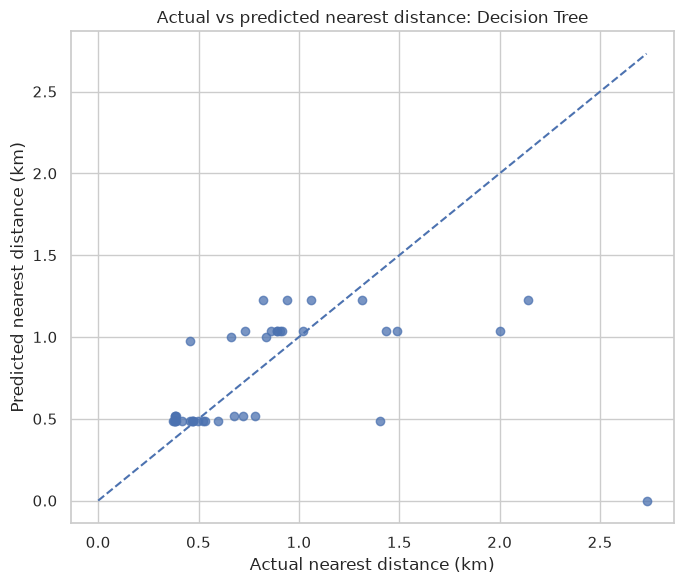

In [16]:
best_model_name = regression_results.iloc[0]["model"]
best_predictions = predictions[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.75)
min_val = min(float(y_test.min()), float(np.min(best_predictions)))
max_val = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.title(f"Actual vs predicted nearest distance: {best_model_name}")
plt.xlabel("Actual nearest distance (km)")
plt.ylabel("Predicted nearest distance (km)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "regression_actual_vs_predicted.png", dpi=160)
plt.show()

## 11. Optional interactive map with Folium

This cell creates an HTML map if Folium is installed. It requires an internet connection when viewing the map tiles. The static coordinate plot above does not require online map tiles.

In [17]:
try:
    import folium
    from folium.plugins import MarkerCluster

    center = [analysis["lat"].mean(), analysis["lng"].mean()]
    station_map = folium.Map(location=center, zoom_start=11, control_scale=True)
    marker_cluster = MarkerCluster().add_to(station_map)

    type_colors = {"MRT": "blue", "LRT": "green"}
    for row in analysis.itertuples():
        popup_text = (
            f"{row.station_name}<br>"
            f"Type: {row.type}<br>"
            f"Nearest station: {row.nearest_station_name}<br>"
            f"Nearest distance: {row.nearest_distance_km:.3f} km"
        )
        folium.CircleMarker(
            location=[row.lat, row.lng],
            radius=5,
            color=type_colors.get(row.type, "gray"),
            fill=True,
            fill_opacity=0.75,
            popup=folium.Popup(popup_text, max_width=300),
        ).add_to(marker_cluster)

    map_path = MAPS_DIR / "singapore_mrt_lrt_stations.html"
    station_map.save(map_path)
    print("Interactive map saved to:", map_path)
except ImportError:
    print("Folium is not installed. Install it with: python -m pip install folium")

Interactive map saved to: /home/rolex/Downloads/singapore-mrt-accessibility-mapper/outputs/maps/singapore_mrt_lrt_stations.html


## 12. Export final analysis table and result files

The analysis table includes the primary dataset's station details, nearest-station distances, nearby-station counts, and cluster labels.

In [18]:
final_columns = [
    "station_name", "type", "lat", "lng",
    "nearest_station_name", "nearest_station_type",
    "nearest_distance_km", "nearest_distance_m",
    "stations_within_500m", "stations_within_1km", "cluster",
]
final_results = analysis[final_columns].sort_values("nearest_distance_km")
final_csv = RESULTS_DIR / "station_accessibility_analysis.csv"
final_results.to_csv(final_csv, index=False)

print("Final analysis saved to:", final_csv)
print("\nOutput files:")
for folder in [PROCESSED_DIR, FIGURES_DIR, MAPS_DIR, RESULTS_DIR]:
    print(f"\n{folder.relative_to(PROJECT_DIR)}/")
    for file in sorted(folder.iterdir()):
        if file.is_file():
            print(" -", file.name)
display(final_results.head(15))

Final analysis saved to: /home/rolex/Downloads/singapore-mrt-accessibility-mapper/outputs/results/station_accessibility_analysis.csv

Output files:

data/processed/
 - mrt_lrt_stations_clean.csv
 - mrt_lrt_stations_with_distances.csv

outputs/figures/
 - kmeans_model_selection.png
 - kmeans_station_clusters.png
 - nearest_distance_by_type.png
 - nearest_distance_histogram.png
 - regression_actual_vs_predicted.png
 - station_counts_by_type.png
 - station_geographical_scatter.png

outputs/maps/
 - singapore_mrt_lrt_stations.html

outputs/results/
 - invalid_primary_records.csv
 - kmeans_cluster_summary.csv
 - proximity_summary_by_type.csv
 - regression_model_metrics.csv
 - station_accessibility_analysis.csv
 - station_name_match_audit.csv


,station_name,type,lat,lng,nearest_station_name,nearest_station_type,nearest_distance_km,nearest_distance_m,stations_within_500m,stations_within_1km,cluster
7,Woodlands,MRT,1.436984,103.786406,Admiralty,MRT,0.000000,0.000000,1,1,7
8,Admiralty,MRT,1.436984,103.786406,Woodlands,MRT,0.000000,0.000000,1,1,7
107,Bencoolen,MRT,1.298477,103.849984,Bras Basah,MRT,0.185436,185.435522,2,9,3
72,Bras Basah,MRT,1.296978,103.850715,Bencoolen,MRT,0.185436,185.435522,2,8,3
156,Soo Teck,LRT,1.405436,103.897287,Sumang,LRT,0.370970,370.970214,1,4,0
155,Sumang,LRT,1.408501,103.898605,Soo Teck,LRT,0.370970,370.970214,2,5,0
150,Sam Kee,LRT,1.409808,103.904920,Teck Lee,LRT,0.377982,377.981642,1,8,0
151,Teck Lee,LRT,1.412783,103.906565,Sam Kee,LRT,0.377982,377.981642,2,6,0
22,City Hall,MRT,1.293119,103.852089,Esplanade,MRT,0.380314,380.314023,2,8,3
73,Esplanade,MRT,1.293995,103.855396,City Hall,MRT,0.380314,380.314023,1,5,3


## 13. Conclusion template

After running all cells, use the actual outputs to write your final conclusions. Do not copy assumed numbers from a sample report.

Discuss:
- How many valid station records remained after cleaning.
- How MRT and LRT records are distributed in the supplied dataset.
- Which records have the smallest and largest nearest-neighbour distances.
- How the K-Means groups are distributed geographically.
- The Welch test result and its limitations.
- Regression MAE/RMSE and why coordinate-only prediction is limited.

### Limitations
1. Kaggle dataset coverage, age, and licence conditions must be checked on the original pages.
2. The two sources may overlap and use different station naming conventions.
3. The supplementary file's station codes may represent interchanges with multiple line identifiers.
4. Coordinate distance is not equivalent to walking distance or travel time.
5. K-Means cluster boundaries depend on the selected value of k and the coordinate representation.
6. A random train/test split may overestimate model generalization because of spatial dependence.
7. The notebook analyzes the supplied files; it does not claim that they represent the complete current Singapore rail network.

